In [1]:
#| include: false
# Disable tqdm progress bars; this is a hidden cell on the docs page
import os

os.environ["TQDM_DISABLE"] = "1"

# Show one value per region on slices

`plot_scalar_on_slice` colours each region by its value on a coronal, sagittal or horizontal slice, or on a top view of the brain. The examples use stand-in values, one for each Beryl region; replace `acronyms` and `values` with your own. For the input the plotting functions take, see [Show one value per region: choose a view](show-one-value-per-region.ipynb).

In [2]:
import matplotlib.pyplot as plt
import numpy as np

from iblatlas.atlas import AllenAtlas
from iblatlas.plots import plot_scalar_on_slice

ba = AllenAtlas()
br = ba.regions

# Stand-in values: one per Beryl region
acronyms = br.acronym[np.unique(br.mappings['Beryl'])]
acronyms = acronyms[~np.isin(acronyms, ['void', 'root'])]
values = np.random.default_rng(0).random(acronyms.size)

## Example 1: Coronal slices

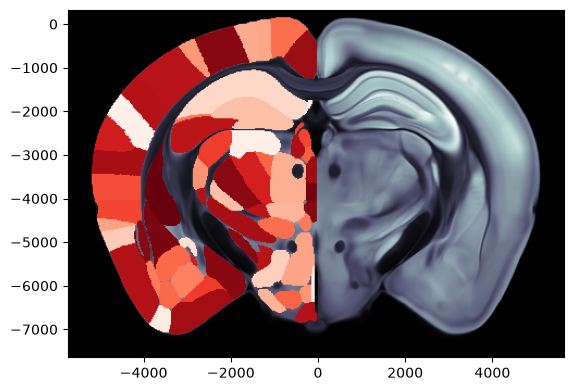

In [3]:
# Plot region values on the left hemisphere of a coronal slice at ap=-2000um overlaid on the dwi Allen image
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-2000, slice='coronal', mapping='Beryl', hemisphere='left',
                               background='image', cmap='Reds', brain_atlas=ba)

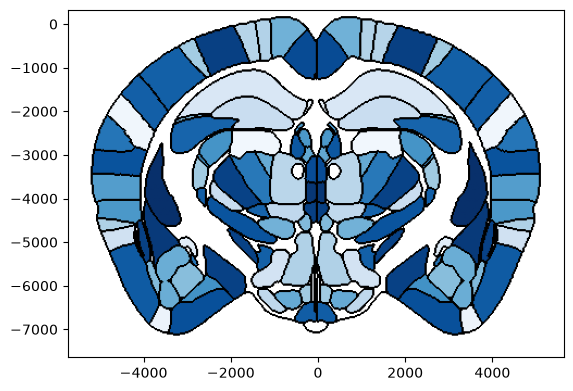

In [4]:
# Plot single column region values on both hemispheres of a coronal slice at ap=-2000um overlaid on brain region boundaries
# If values only contains one column, the values will be mirrored on each hemisphere
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-2000, slice='coronal', mapping='Beryl',
                               hemisphere='both', background='boundary', cmap='Blues', brain_atlas=ba)

To show different values in each hemisphere, see [Show different values in each hemisphere](show-different-values-in-each-hemisphere.ipynb).

## Example 2: Sagittal slices

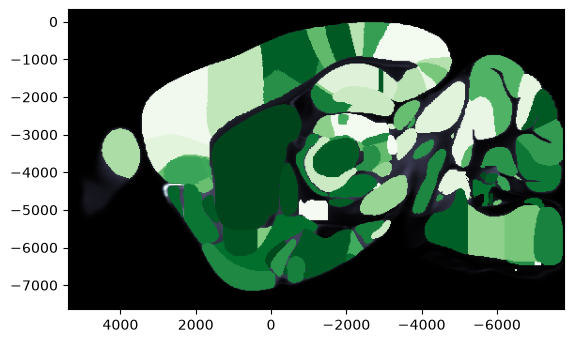

In [5]:
# Plot region values on the left hemisphere of a sagittal slice at ml=-2000um overlaid on the dwi Allen image
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-2000, slice='sagittal', mapping='Beryl',
                               hemisphere='left', background='image', cmap='Greens', brain_atlas=ba)

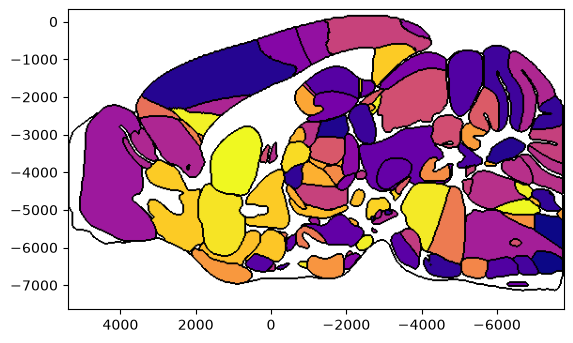

In [6]:
# Plot region values on the left hemisphere of a sagittal slice at ml=-1000um overlaid on brain region boundaries
# Create figure before and pass in axis on which to plot
fig, ax = plt.subplots()
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-1000, slice='sagittal', mapping='Beryl', hemisphere='left',
                               background='boundary', cmap='plasma', brain_atlas=ba, ax=ax)

## Example 3: Horizontal slices

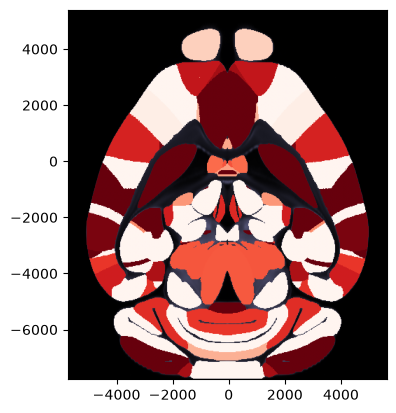

In [7]:
# Plot region values on both hemispheres of a horizontal slice at dv=-2500um overlaid on the dwi Allen image
# Pass in clevels min max values to cap the colormap
fig, ax = plot_scalar_on_slice(acronyms, values, coord=-2500, slice='horizontal', mapping='Beryl', hemisphere='both',
                               background='image', cmap='Reds', brain_atlas=ba, clevels=[0.25, 0.75])

## Example 4: Top view

The top view shows, at each position, the region at the brain's surface.

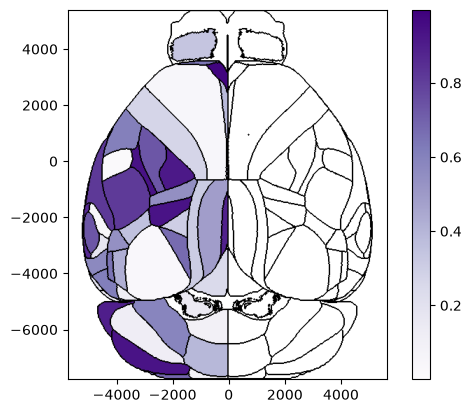

In [8]:
# Plot region values on left hemisphere of a top view overlaid on brain region boundaries and show cbar
fig, ax, cbar = plot_scalar_on_slice(acronyms, values, slice='top', mapping='Beryl', hemisphere='left',
                                     background='boundary', cmap='Purples', brain_atlas=ba, show_cbar=True)